# 02 - Global Modelling (predictive analysis)
We compare five model families - **Linear Regression** (baseline), **Decision Tree**, **Random Forest**, **XGBoost** and an **MLP** (a small feed-forward neural network) - under two different train/test splits. The heavy training is done by `python -m src.train`; this notebook reads its saved results and analyses them.

In [1]:
import sys; sys.path.append("..")
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display, Image
from src import config as C, data, evaluate
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)

## 1. Did a log-transformed target help?
We tested `log1p(yield)` per model using only *training-year* cross-validation (the test set was never used for this decision). Metrics are always reported in original units.

In [2]:
lt = pd.read_csv(C.RESULTS_DIR / "log_target_experiment.csv").pivot(index="model", columns="log_target", values="cv_R2")
lt.columns = ["raw target CV R2", "log target CV R2"]; display(lt.round(3))
top = json.loads((C.RESULTS_DIR / "top_models.json").read_text()); print("kept log target for:", [k for k, v in top["log_choice"].items() if v])

,raw target CV R2,log target CV R2
model,,
DecisionTree,0.931,0.934
LinearRegression,0.745,0.761
MLP,0.887,-4.784
RandomForest,0.953,0.948
XGBoost,0.950,0.935


kept log target for: ['LinearRegression']


Only plain Linear Regression benefits (it cannot bend to a skewed target); tree models and the MLP do not need it, so they use the raw target.

## 2. Model comparison - both splits

In [3]:
comp = pd.read_csv(C.GLOBAL_COMPARISON_CSV)
cols = ["model", "cv_R2_mean", "cv_R2_std", "test_R2", "test_MAE", "test_RMSE", "train_time_s"]
for s, name in [("random", "Random 80/20 split"), ("time", "Time-based split (test = last 4 years)")]:
    print("\n==", name); display(comp[comp.split == s][cols].round(3).reset_index(drop=True))


== Random 80/20 split


,model,cv_R2_mean,cv_R2_std,test_R2,test_MAE,test_RMSE,train_time_s
0,LinearRegression,0.770,0.010,0.776,22682.090,40250.010,0.045
1,DecisionTree,0.976,0.004,0.976,4199.062,13120.316,0.082
2,RandomForest,0.985,0.002,0.984,4013.476,10672.207,1.446
3,XGBoost,0.974,0.002,0.974,7836.832,13755.629,0.617
4,MLP,0.954,0.006,0.961,8671.715,16822.028,8.603
5,RandomForest (tuned),0.984,0.002,0.983,4657.917,11202.755,0.996
6,XGBoost (tuned),0.986,0.001,0.986,4414.397,10236.611,1.547



== Time-based split (test = last 4 years)


,model,cv_R2_mean,cv_R2_std,test_R2,test_MAE,test_RMSE,train_time_s
0,LinearRegression,0.767,0.014,0.709,28689.371,51349.722,0.038
1,DecisionTree,0.935,0.014,0.936,11518.027,24044.682,0.082
2,RandomForest,0.957,0.007,0.955,10409.940,20306.313,1.411
3,XGBoost,0.955,0.004,0.951,12286.857,21170.246,0.602
4,MLP,0.903,0.036,0.934,14157.890,24544.244,8.766
5,RandomForest (tuned),0.955,0.007,0.953,10838.375,20743.712,1.007
6,XGBoost (tuned),0.960,0.003,0.957,10370.513,19671.442,1.629


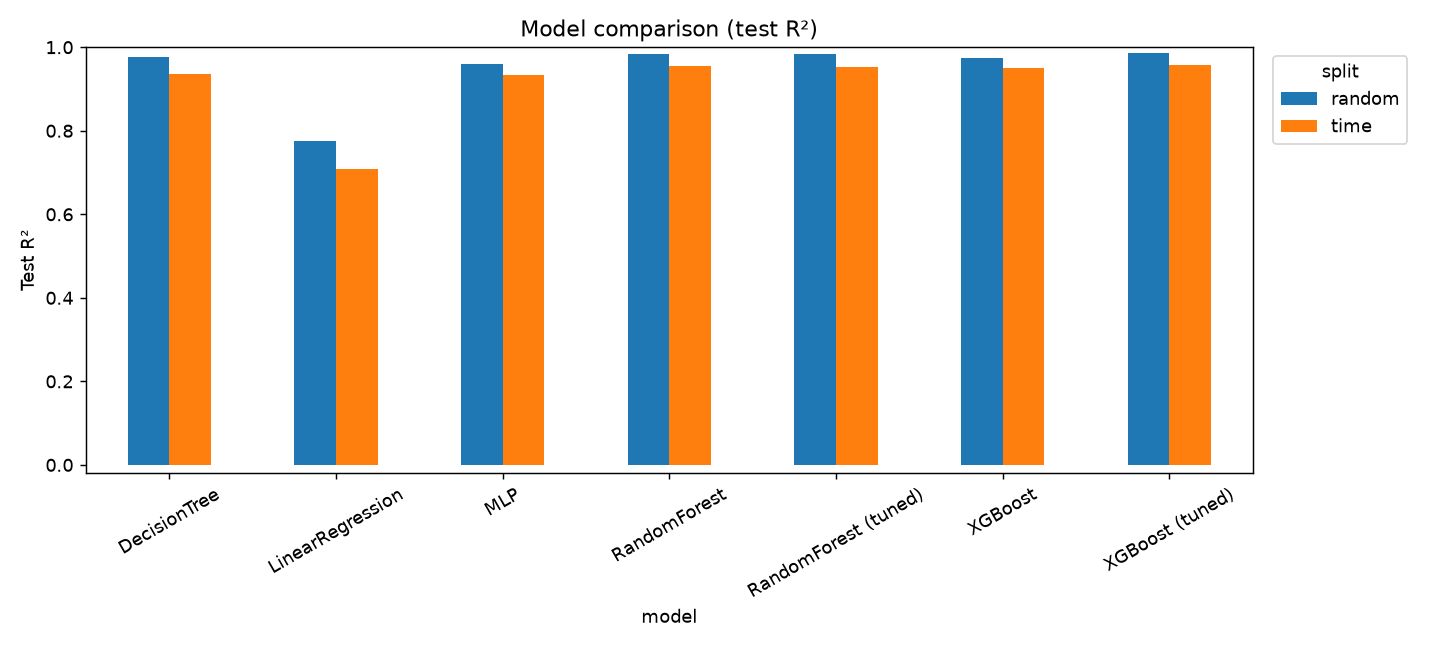

In [4]:
display(Image(str(C.FIG_DIR / "model_comparison.png")))

**How to read the table.** `cv_R2` is 5-fold cross-validation on the training set (shuffled folds for the random split; *forward-chaining by year* for the time split so a fold never trains on the future). `test_*` are measured on held-out data and are in original units (hg/ha). **Random Forest and XGBoost** (the two strongest families) were tuned with `RandomizedSearchCV` (20 iterations) on **both** splits, so every model in the table and chart has a random-split bar and a time-split bar; tuned versions are marked `(tuned)`.

In [5]:
print(json.dumps(top["tuned_params"], indent=1, default=str)[:1800])

{
 "random": {
  "RandomForest": {
   "model__max_depth": 20,
   "model__max_features": 1.0,
   "model__min_samples_leaf": 1,
   "model__n_estimators": 149
  },
  "XGBoost": {
   "model__colsample_bytree": 0.8736600550686904,
   "model__learning_rate": 0.0862496209572722,
   "model__max_depth": 10,
   "model__n_estimators": 609,
   "model__subsample": 0.9861021229056552
  }
 },
 "time": {
  "RandomForest": {
   "model__max_depth": 20,
   "model__max_features": 1.0,
   "model__min_samples_leaf": 1,
   "model__n_estimators": 149
  },
  "XGBoost": {
   "model__colsample_bytree": 0.9162213204002109,
   "model__learning_rate": 0.035543498097189236,
   "model__max_depth": 10,
   "model__n_estimators": 643,
   "model__subsample": 0.6733618039413735
  }
 }
}


## 3. Best model - predicted vs actual and residuals (time-based test set)

Best model (highest time-split CV R2): XGBoost (tuned)


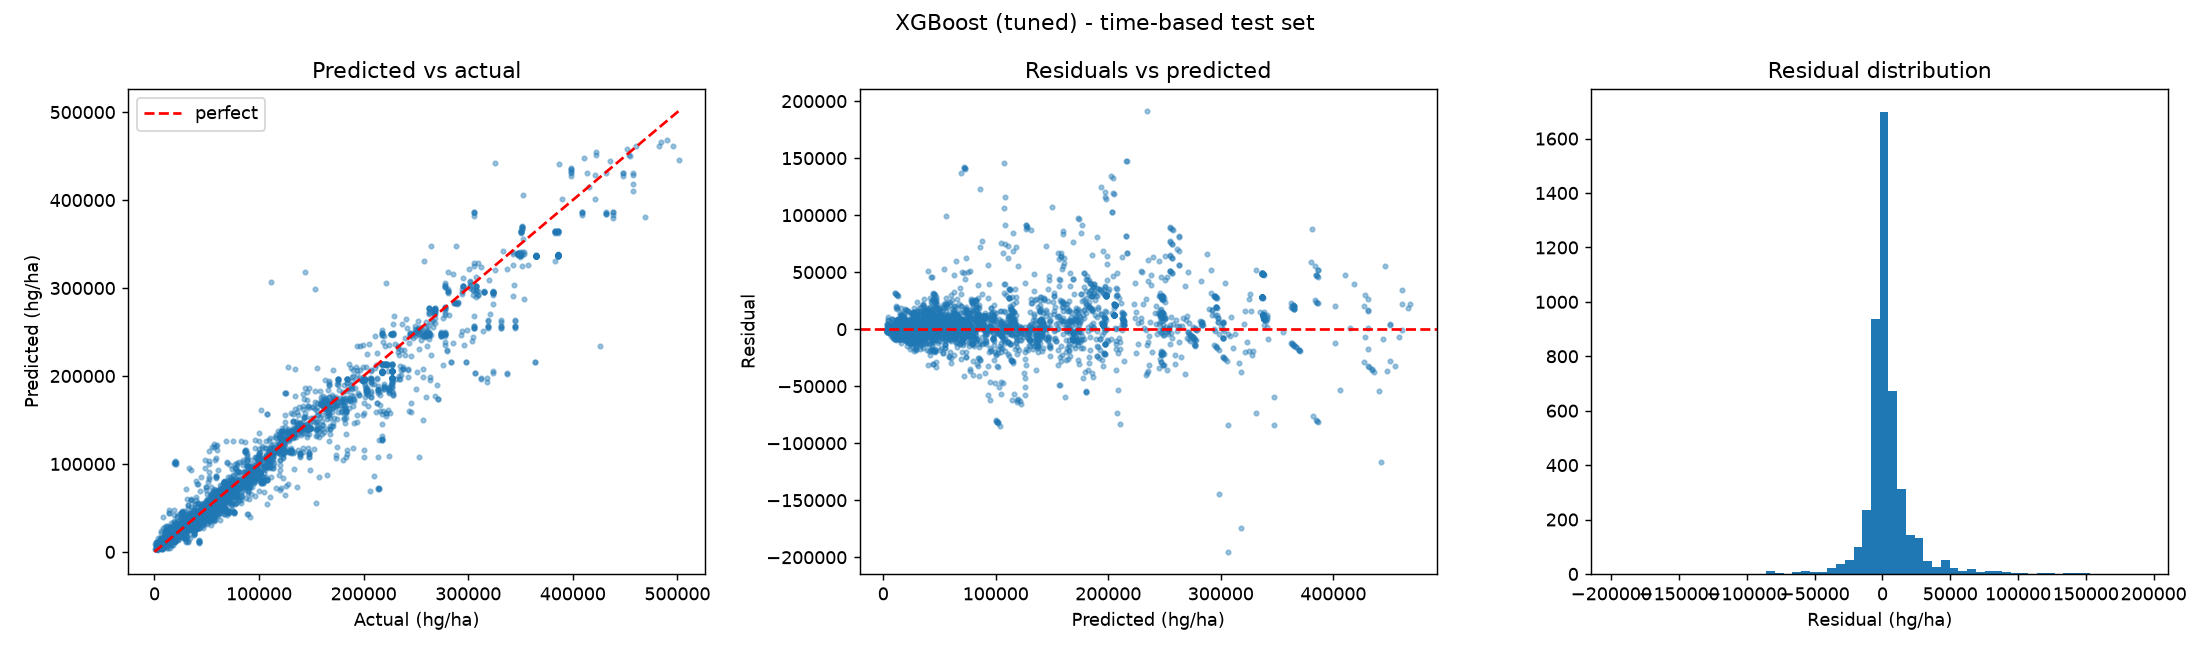

In [6]:
best_name = top["best_global"]; print("Best model (highest time-split CV R2):", best_name)
display(Image(str(C.FIG_DIR / "best_pred_vs_actual.png")))

Points hug the diagonal; the model under-predicts the very highest yields (potato/cassava in high-yield countries), visible as the fan-shape in the residuals. Errors are not centred perfectly at 0 for large yields, because there are few such examples.

## 4. KEY FINDING - why the random split scores higher
We measure how 'leaky' each split is. For each test row we check whether the training set contains the **same country-crop pair in the neighbouring years** (year-1 AND year+1) - which lets a model simply interpolate.

In [7]:
df = data.clean(verbose=False)
splits = {"random": data.random_split(df), "time": data.time_split(df)}
def leak_stats(tr, te):
    key = lambda d: set(zip(d.Area, d.Item, d.Year))
    ktr = key(tr)
    pair_seen = np.mean([(a, i) in set(zip(tr.Area, tr.Item)) for a, i, _ in zip(te.Area, te.Item, te.Year)])
    sandwiched = np.mean([((a, i, y - 1) in ktr) and ((a, i, y + 1) in ktr) for a, i, y in zip(te.Area, te.Item, te.Year)])
    prev = np.mean([(a, i, y - 1) in ktr for a, i, y in zip(te.Area, te.Item, te.Year)])
    return {"pair seen in train": pair_seen, "year-1 in train": prev, "year-1 AND year+1 in train": sandwiched}
leak = pd.DataFrame({k: leak_stats(*v) for k, v in splits.items()}).T
display((leak * 100).round(1).add_suffix(" (%)"))

# How much is plain memorisation? Predict each test row by the TRAIN mean of its country-crop pair.
rows = []
for k, (tr, te) in splits.items():
    pm = tr.groupby(["Area", "Item"])[C.G_TARGET].mean()
    p = [pm.get((a, i), tr[C.G_TARGET].mean()) for a, i in zip(te.Area, te.Item)]
    rows.append({"split": k, **{f"pair-mean baseline {m}": v for m, v in evaluate.regression_metrics(te[C.G_TARGET], p).items()}})
display(pd.DataFrame(rows).set_index("split").round(3))

,pair seen in train (%),year-1 in train (%),year-1 AND year+1 in train (%)
random,100.0,84.7,71.1
time,99.1,24.8,0.0


,pair-mean baseline R2,pair-mean baseline MAE,pair-mean baseline RMSE
split,,,
random,0.939,11077.570,21060.471
time,0.889,17859.345,31709.200


In [8]:
base = best_name   # the tuned model now exists on BOTH splits, so we compare like with like
r_ = comp[(comp.split == "random") & (comp.model == base)].iloc[0]
t_ = comp[(comp.split == "time") & (comp.model == best_name)].iloc[0]
rf = comp[(comp.model == "RandomForest") & (~comp.tuned)].set_index("split")
display(Markdown(f'''**Result.** The same model family scores higher on the random split. Random Forest: test R² **{rf.loc["random","test_R2"]:.3f}** (random) vs **{rf.loc["time","test_R2"]:.3f}** (time), and RMSE rises from {rf.loc["random","test_RMSE"]:,.0f} to {rf.loc["time","test_RMSE"]:,.0f} hg/ha. {best_name}: R² {r_.test_R2:.3f} (random) → {t_.test_R2:.3f} (time).

**Why.**
1. Yield of a country-crop pair is extremely *persistent* (Japan's potatoes are high every year). A random split scatters the years of each pair across train and test, so for **{leak.loc["random","year-1 AND year+1 in train"]*100:.0f}%** of test rows the model has already seen the same pair in BOTH the previous and next year. Tree models can almost look the answer up. This is **data leakage** of the temporal/pair kind.
2. A trivial "average yield of this pair" lookup already reaches R² of {pd.DataFrame(rows).set_index("split").loc["random","pair-mean baseline R2"]:.2f} on the random split - the model is rewarded for memorising, not for understanding weather.
3. In the time-based split the test years are strictly in the future: the year+1 neighbour is never available ({leak.loc["time","year-1 AND year+1 in train"]*100:.0f}% sandwiched), and trends, new technology and shifting climate have moved the numbers. This is exactly the situation of a real forecaster.

**Conclusion.** The time-based split is the more honest estimate of real-world performance, so we **select the best model on it**, and report the random-split score only as an optimistic upper bound.'''))

**Result.** The same model family scores higher on the random split. Random Forest: test R² **0.984** (random) vs **0.955** (time), and RMSE rises from 10,672 to 20,306 hg/ha. XGBoost (tuned): R² 0.986 (random) → 0.957 (time).

**Why.**
1. Yield of a country-crop pair is extremely *persistent* (Japan's potatoes are high every year). A random split scatters the years of each pair across train and test, so for **71%** of test rows the model has already seen the same pair in BOTH the previous and next year. Tree models can almost look the answer up. This is **data leakage** of the temporal/pair kind.
2. A trivial "average yield of this pair" lookup already reaches R² of 0.94 on the random split - the model is rewarded for memorising, not for understanding weather.
3. In the time-based split the test years are strictly in the future: the year+1 neighbour is never available (0% sandwiched), and trends, new technology and shifting climate have moved the numbers. This is exactly the situation of a real forecaster.

**Conclusion.** The time-based split is the more honest estimate of real-world performance, so we **select the best model on it**, and report the random-split score only as an optimistic upper bound.

**Note on honesty:** the gap is real but moderate (a few R² points) because the models also learn real structure (crop, country, and climate effects) that survives into the future. Absolute errors (MAE/RMSE), not only R², show the gap most clearly.